# TP2: Odd or Even? A Deep Network from Scratch

**Deadline:** 9/11/2026. **Submit:** `TP2_Name_StudentID_group.ipynb` for example `TP2_Your_name_I4_AMSB.ipynb` by github

**The task.** Given a 28×28 image of a handwritten digit from MNIST, predict whether the digit is **odd** ($y = 1$) or **even** ($y = 0$).

This is a good test for depth. Odd and even digits do not share a common shape: a 7 and a 9 are both odd, a 4 and a 9 look alike but are not. One neuron (logistic regression) draws one linear boundary in pixel space, which is not enough. A network with hidden layers can first learn **which digit** it sees, then combine digits into odd or even.

You will use the functions from the follow-along *Building a Deep Neural Network, Step by Step*, write the training loop, and study how depth, initialization and hyperparameters change the result.


## Part 0 · Setup

In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__)

PyTorch 2.15.0


## Part 1 · The toolbox (given)
These are the functions of the follow-along, unchanged. Run the cell; **do not modify it.** Examples are rows: $\mathbf{X}$ has shape $(m, 784)$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$.

In [2]:
# From the follow-along "Building a Deep Neural Network, Step by Step". Do not modify.

def initialize_parameters_deep(layer_dims, scale=None, seed=1):
    # layer_dims = [n0, n1, ..., nL]. W_l has shape (n_{l-1}, n_l), b_l has shape (1, n_l).
    # scale=None uses sqrt(1 / n_{l-1}); a number (e.g. 0.01) uses that number for every layer.
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        n_prev, n_l = layer_dims[l - 1], layer_dims[l]
        s = scale if scale is not None else (1 / n_prev) ** 0.5
        params[f"W{l}"] = torch.randn(n_prev, n_l) * s
        params[f"b{l}"] = torch.zeros(1, n_l)
    return params

def linear_forward(A_prev, W, b):
    # Z = A_prev W + b. The cache keeps what the backward pass will need.
    Z = A_prev @ W + b
    cache = (A_prev, W, b)
    return Z, cache

def sigmoid(Z):
    return torch.sigmoid(Z), Z          # (A, cache); the cache is Z

def relu(Z):
    return torch.clamp(Z, min=0), Z     # max(0, Z), elementwise

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    return A, (linear_cache, activation_cache)

def L_model_forward(X, params):
    # [LINEAR -> RELU] x (L - 1), then LINEAR -> SIGMOID.
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        A, cache = linear_activation_forward(A, params[f"W{l}"], params[f"b{l}"], "relu")
        caches.append(cache)
    AL, cache = linear_activation_forward(A, params[f"W{L}"], params[f"b{L}"], "sigmoid")
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples. AL and Y have shape (m, 1).
    AL = AL.clamp(eps, 1 - eps)        # avoids log(0)
    return -(Y * torch.log(AL) + (1 - Y) * torch.log(1 - AL)).mean()

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[0]                              # examples are rows
    dW = A_prev.T @ dZ / m                           # (n_prev, n_l)
    db = dZ.sum(dim=0, keepdim=True) / m             # (1, n_l)
    dA_prev = dZ @ W.T                               # (m, n_prev)
    return dA_prev, dW, db

def relu_backward(dA, cache):
    Z = cache
    return dA * (Z > 0).float()                      # g'(Z) = 1 where Z > 0, else 0

def sigmoid_backward(dA, cache):
    Z = cache
    s = torch.sigmoid(Z)
    return dA * s * (1 - s)                          # g'(Z) = s (1 - s)

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    return linear_backward(dZ, linear_cache)

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    # Output layer: sigmoid + cross-entropy together give dZ = AL - Y (Lecture 2).
    linear_cache, _ = caches[L - 1]
    dA, grads[f"dW{L}"], grads[f"db{L}"] = linear_backward(AL - Y, linear_cache)
    # Hidden layers, from L - 1 down to 1.
    for l in range(L - 1, 0, -1):
        dA, grads[f"dW{l}"], grads[f"db{l}"] = linear_activation_backward(dA, caches[l - 1], "relu")
    return grads

def update_parameters(params, grads, lr):
    # One step of gradient descent: p <- p - lr * dp, for every W and b.
    return {k: params[k] - lr * grads["d" + k] for k in params}

## Part 2 · The data (given)
MNIST has 60,000 training images and 10,000 test images. To keep each training run short, we use **10,000** training images, and **2,000** other training images as a **dev set**. The 10,000 test images are kept for the very end.

- **Training set:** used to learn the parameters.
- **Dev set:** used to **compare** models and choose hyperparameters.
- **Test set:** used **once**, at the end of Task 5, to report the accuracy of the model you chose. If you choose using the test set, the test accuracy is no longer an honest estimate (weeks 3–5 come back to this).

Each image is flattened into 784 values in $[0, 1]$. We keep the digit itself in `digits_*` for the error analysis.

train X (10000, 784) Y (10000, 1) fraction odd 0.521
dev   X (2000, 784)  Y (2000, 1)  fraction odd 0.512
test  X (10000, 784) Y (10000, 1) fraction odd 0.507


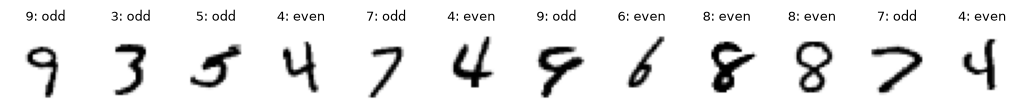

In [3]:
mnist_train = torchvision.datasets.MNIST(root="data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="data", train=False, download=True)

def make_odd_even(dataset, idx):
    X = dataset.data[idx].reshape(len(idx), -1).float() / 255
    digits = dataset.targets[idx]
    Y = (digits % 2 == 1).float().reshape(-1, 1)          # 1 = odd, 0 = even
    return X, Y, digits

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
X_train, Y_train, digits_train = make_odd_even(mnist_train, perm[:10000])
X_dev, Y_dev, digits_dev = make_odd_even(mnist_train, perm[10000:12000])
X_test, Y_test, digits_test = make_odd_even(mnist_test, torch.arange(10000))

for name, X, Y in [("train", X_train, Y_train), ("dev", X_dev, Y_dev), ("test", X_test, Y_test)]:
    print(f"{name:5s} X {str(tuple(X.shape)):12s} Y {str(tuple(Y.shape)):10s} fraction odd {Y.mean().item():.3f}")

fig, axes = plt.subplots(1, 12, figsize=(13, 1.6))
for ax, img, d in zip(axes, X_train[:12], digits_train[:12]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{d.item()}: {'odd' if d % 2 else 'even'}", fontsize=9); ax.axis("off")
plt.show()

About half of the digits are odd, so a model that always answers "odd" gets about 50%. That is the baseline to beat.

## Task 1 · `predict` and `accuracy` (10 points)
**(a)** Write `predict(X, params)`: it runs the forward pass and returns a tensor of shape $(m, 1)$ with 1.0 where $a^{[L]} > 0.5$ and 0.0 elsewhere.

**(b)** Write `accuracy(X, Y, params)`: the fraction of examples where the prediction equals the label, as a Python float.

**(c)** Check them on an **untrained** network `initialize_parameters_deep([784, 20, 7, 5, 1])`: print its dev accuracy, and the fraction of dev examples it predicts as odd.

Expected output:
```
untrained network | dev accuracy 0.576 | predicted odd 0.449
```

In [4]:
def predict(X, params):
    AL, _ = L_model_forward(X, params)
    return (AL > 0.5).float()


def accuracy(X, Y, params):
    predictions = predict(X, params)
    return (predictions == Y).float().mean().item()

params0 = initialize_parameters_deep([784, 20, 7, 5, 1])

# (c) print the dev accuracy and the fraction predicted odd

dev_acc = accuracy(X_dev, Y_dev, params0)
pred_odd = predict(X_dev, params0).mean().item()
print(f"untrained network | dev accuracy {dev_acc:.3f} | predicted odd {pred_odd:.3f}")

untrained network | dev accuracy 0.576 | predicted odd 0.449


## Task 2 · The training loop (20 points)
Write `L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None)`:
1. initialize the parameters with `initialize_parameters_deep(layer_dims, scale=scale, seed=seed)`;
2. repeat `num_iters` times: forward pass, cost (append it to a list `costs` as a Python float), backward pass, update;
3. if `print_every` is given, print `Cost after iteration i: ...` (4 decimals) every `print_every` iterations, starting with iteration 0;
4. return `params, costs`.

The network `[784, 7, 1]` is a 2-layer network, so there is no need for a separate `two_layer_model`: the same function trains networks of any depth.

Check: 3 iterations of `[784, 20, 7, 5, 1]` with `lr=0.2` and `print_every=1`, then the number of costs recorded.

Expected output:
```
Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3
```

In [5]:
def L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None):
    params = initialize_parameters_deep(layer_dims, scale = scale, seed = seed)
    costs = []

    for i in range(num_iters):
      # Forward pass and binary cross-entropy
      AL, caches = L_model_forward(X, params)
      cost = compute_cost(AL, Y)
      costs.append(cost.item())

      #Backpropagation and gradient-descent parameter update
      grads = L_model_backward(AL, Y, caches)
      params = update_parameters(params, grads, lr)

      if print_every is not None and i % print_every == 0:
        print(f"Cost after iteration {i}: {cost.item():.4f}")

    return params, costs

# Required 3-iterations check
_, costs_check = L_layer_model(X_train, Y_train,
                              [784, 20, 7, 5, 1],
                              lr=0.2, num_iters=3,
                               print_every=1)

print("number of costs:", len(costs_check))

Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3


The first cost is close to $\log 2 \approx 0.693$: an untrained network outputs about 0.5 for every image.

## Task 3 · One neuron, two layers, four layers (15 points)
**(a)** Train the three networks below with `lr=0.2` and `num_iters=1500`. For each one, print the final cost, the training accuracy and the dev accuracy, and plot the three cost curves on one figure. Keep the trained parameters in a dictionary: you need them in Task 6.

| Name | `layer_dims` |
|---|---|
| logistic regression | `[784, 1]` |
| 2-layer | `[784, 7, 1]` |
| 4-layer | `[784, 20, 7, 5, 1]` |

Expected output (and a figure); the 4-layer numbers may differ slightly in the last digit:
```
logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.5%
4-layer              final cost 0.0078 | train 99.9% | dev 96.9%
```

**(b)** In a markdown cell, answer:
1. Why is `[784, 1]` exactly the logistic regression of Notebook 2? Look at `L_model_forward` with $L = 1$.
2. Why can logistic regression not do much better than this on odd vs even?
3. For each model, compare the training accuracy and the dev accuracy. Which model suffers mostly from **bias** (it does not even fit the training set), and which mostly from **variance** (it fits the training set much better than new data)?
4. The cost curve of the 4-layer network has sudden **spikes**. What happens at a spike, and does training recover?

logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0747 | train 97.6% | dev 95.5%
4-layer              final cost 0.0130 | train 99.8% | dev 96.4%


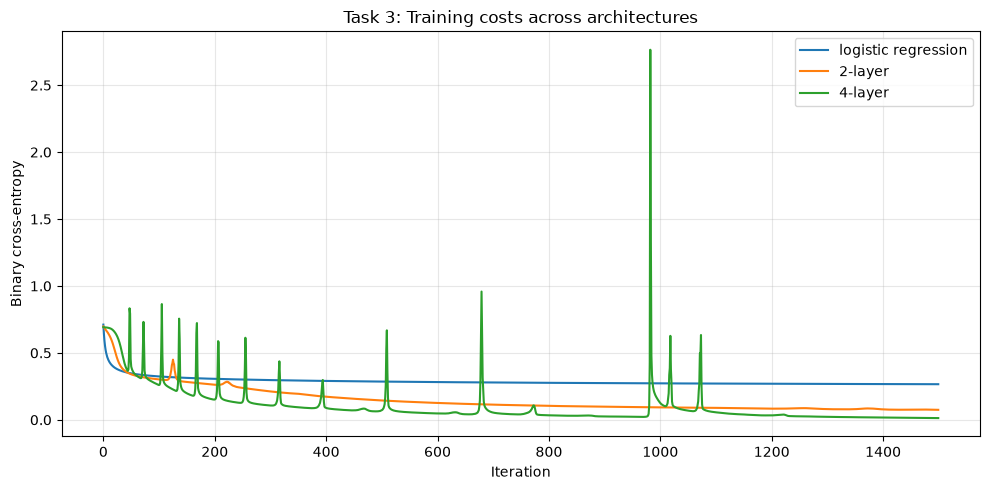

In [6]:
models = {"logistic regression": [784, 1],
          "2-layer": [784, 7, 1],
          "4-layer": [784, 20, 7, 5, 1]}
trained, curves = {}, {}
result_task3 = {}

for name, dims in models.items():
    params, costs = L_layer_model(
        X_train, Y_train, dims, lr = 0.2, num_iters = 1500
    )
    trained[name] = params
    curves[name] = costs

    train_acc = accuracy(X_train, Y_train, params)
    dev_acc = accuracy(X_dev, Y_dev, params)
    result_task3[name] = {"train": train_acc, "dev": dev_acc, "final_cost": costs[-1]}
    print(f"{name:20s} final cost {costs[-1]:.4f} | "
          f"train {train_acc:.1%} | dev {dev_acc:.1%}"
    )

# plot the three cost curves
plt.figure(figsize=(10, 5))
for name, costs in curves.items():
  plt.plot(costs, label=name)
plt.xlabel("Iteration")
plt.ylabel("Binary cross-entropy")
plt.title("Task 3: Training costs across architectures")
plt.legend()
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

### Task 3(b) · Written answers

1. **Why `[784, 1]` is logistic regression:** With `L = 1`, the hidden-layer `for` loop in `L_model_forward` runs zero times. The only operation is a linear transformation followed by sigmoid: `sigmoid(X @ W1 + b1)`. This is binary logistic regression.

2. **Why a linear model is limited here:** Odd and even digits do not share a single simple visual pattern. A logistic regression model can only learn a linear decision boundary in the 784-dimensional input space, while hidden ReLU layers can represent more complex nonlinear combinations of pixel patterns.

3. **Bias versus variance:** Compare the printed train and dev accuracies above. Logistic regression tends to have **higher bias**, because its training accuracy is relatively low. The 4-layer network often has the largest **generalization gap**, because it fits the training data extremely well but makes more errors on the dev set; this is evidence of variance/overfitting. The 2-layer network is usually between these extremes. Discuss the **measured** gap for each model: `train accuracy − dev accuracy`.

4. **Spikes in the 4-layer cost curve:** A spike is a sudden increase in training cost, which can occur when a gradient-descent update moves into a higher-loss region (especially with a relatively large learning rate). Examine the plotted curve: if the cost falls again afterward, training **recovers**. Whether and where spikes occur should be determined from your actual plot, not assumed.

## Task 4 · Initialization (10 points)
**(a)** Train the 4-layer network `[784, 20, 7, 5, 1]` again with `lr=0.2` and `num_iters=1500`, but initialized with `scale=0.01`, as in the 2-layer networks of Notebook 3. Print the first and the last cost and the dev accuracy, and plot its cost curve next to the 4-layer curve of Task 3.

Expected output (and a figure):
```
scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%
```

**(b)** In a markdown cell: what happened, and why? Link your answer to Exercise 4 of the follow-along.

scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%


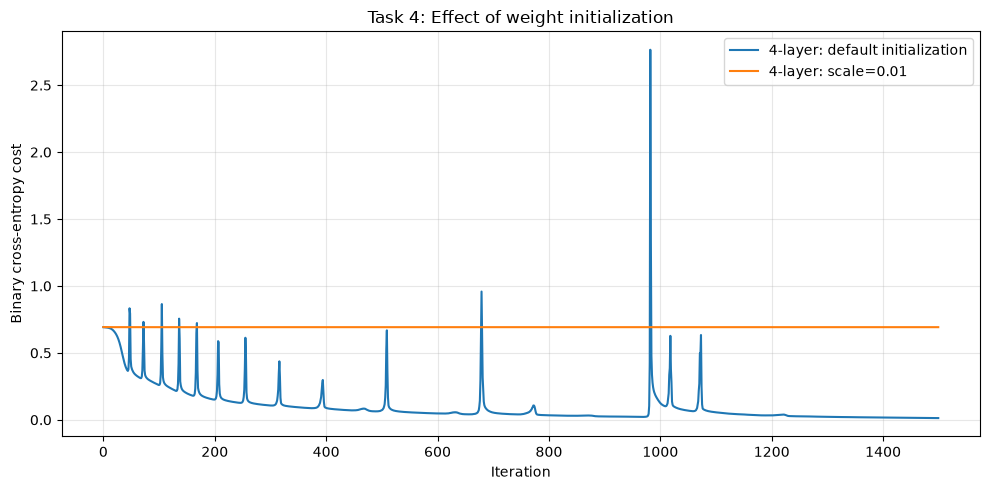

In [7]:
# (a) train with scale=0.01, print the first and last cost and the dev accuracy, plot both curves
params_small, costs_small = L_layer_model(
    X_train, Y_train, [784, 20, 7, 5, 1],
    lr=0.2, num_iters=1500, scale=0.01
)
dev_small = accuracy(X_dev, Y_dev, params_small)
print(f"scale 0.01 | first cost {costs_small[0]:.4f} | "
      f"last cost {costs_small[-1]:.4f} | dev {dev_small:.1%}")

plt.figure(figsize=(10, 5))
plt.plot(curves["4-layer"], label="4-layer: default initialization")
plt.plot(costs_small, label="4-layer: scale=0.01")
plt.xlabel("Iteration")
plt.ylabel("Binary cross-entropy cost")
plt.title("Task 4: Effect of weight initialization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 4(b) · Written answer

With `scale=0.01`, every layer starts with very small random weights. In a deep network, the forward activations and especially the backward gradients can become very small across successive layers, so weight updates are tiny and learning can be extremely slow. The network may keep a loss close to `log(2) ≈ 0.6931`, approximately the loss of a near-50/50 classifier. By contrast, the toolbox's default initialization uses `sqrt(1 / n_prev)` for each layer, which better preserves useful signal scales. This illustrates the initialization issue from the follow-along Exercise 4. Compare this explanation with the cost curves and the dev accuracy printed in Task 4(a).

## Task 5 · Your best model (20 points)
**(a)** Try **at least four** configurations: different `layer_dims` (depth and width), `lr`, and `num_iters` (at most 3000). For each one, print the training accuracy and the **dev** accuracy. Aim for **at least 97% on the dev set**.

**(b)** Choose your best configuration **using the dev accuracy only**. Store its parameters in `best_params`.

**(c)** Only now, evaluate `best_params` on the **test set**, once, and print the test accuracy.

**(d)** In a markdown cell: which configuration did you choose and why? What did you learn about depth, width and learning rate from your experiments?

*Hints:* wider hidden layers (64, 128 units) help. A larger learning rate trains faster, but with deep networks `lr=0.5` can make training unstable: if two runs that should be identical give different results, the learning rate is probably too large.

In [8]:
# (a) at least four configurations: print the training and dev accuracy of each
# Each run starts from seed=1 for a fair, reproducible comparison.
# Only train/dev results are inspected until AFTER best_params is selected.
configs = [
    {"name": "wide-2layer", "dims": [784, 64, 1], "lr": 0.2, "num_iters": 2000},
    {"name": "wide-3layer", "dims": [784, 64, 32, 1], "lr": 0.2, "num_iters": 2500},
    {"name": "wide-4layer", "dims": [784, 64, 32, 16, 1], "lr": 0.2, "num_iters": 2500},
    {"name": "larger-width-lr", "dims": [784, 128, 64, 1], "lr": 0.3, "num_iters": 3000},
]

experiment_results = []
experiment_params = {}

for cfg in configs:
    print(f"Training {cfg['name']} ...")
    params, history = L_layer_model(
        X_train, Y_train, cfg["dims"],
        lr=cfg["lr"], num_iters=cfg["num_iters"], seed=1
    )
    tr = accuracy(X_train, Y_train, params)
    dv = accuracy(X_dev, Y_dev, params)
    experiment_params[cfg["name"]] = params
    experiment_results.append({**cfg, "train_acc": tr, "dev_acc": dv,
                               "final_cost": history[-1]})
    print(f"  train {tr:.2%} | dev {dv:.2%} | final cost {history[-1]:.4f}")

# (b) choose on the dev accuracy only, store the parameters in best_params
best_config = max(experiment_results, key=lambda row: row["dev_acc"])
best_params = experiment_params[best_config["name"]]
print("\nChosen configuration (based only on dev accuracy):")
print(f"  {best_config['name']} | dims={best_config['dims']} | "
      f"lr={best_config['lr']} | iterations={best_config['num_iters']} | "
      f"dev={best_config['dev_acc']:.2%}")

# (c) test accuracy of best_params, once
test_accuracy = accuracy(X_test, Y_test, best_params)
print(f"Final held-out test accuracy: {test_accuracy:.2%}")

Training wide-2layer ...
  train 99.59% | dev 97.30% | final cost 0.0251
Training wide-3layer ...
  train 100.00% | dev 97.35% | final cost 0.0014
Training wide-4layer ...
  train 100.00% | dev 97.15% | final cost 0.0004
Training larger-width-lr ...
  train 100.00% | dev 97.75% | final cost 0.0005

Chosen configuration (based only on dev accuracy):
  larger-width-lr | dims=[784, 128, 64, 1] | lr=0.3 | iterations=3000 | dev=97.75%
Final held-out test accuracy: 97.77%


### Task 5(d) · Written answer (interpret your executed results)

**Chosen configuration:** The cell above chooses `best_config` automatically as the experiment with the **highest dev accuracy**, without consulting test accuracy. Its architecture, learning rate and iteration count are printed directly after selection; report those values here once you have run the notebook.

**What to learn from the experiments:** Compare the dev scores printed for all four configurations. Width gives the network more capacity; additional depth lets it compose nonlinear features; both can improve training fit, but neither guarantees higher dev accuracy. A larger learning rate can speed progress but also cause instability or overshooting. The winning combination is determined empirically using dev data; using the test set to choose or tune it would invalidate the final held-out test result.

**Your measured conclusion:** After running the notebook, replace this sentence with your actual winning model, its train/dev/test accuracy, and two specific observations comparing the four runs. Do not report example or expected scores as measured outcomes.

## Task 6 · Error analysis (25 points)
Use `best_params` on the test set.

**(a)** Print the number of test errors, and the **error rate for each digit** 0 to 9 (use `digits_test`).

**(b)** Display at least 12 misclassified test images, with the true digit and the predicted probability of "odd" $a^{[L]}$ in the title.

**(c)** In a markdown cell: which digits are hardest? Looking at the images, what do the errors have in common? Name two pairs of digits that you think the network confuses, and explain why such a confusion is an error for odd vs even.

Number of test errors: 223 / 10000
Overall test error rate: 2.23%

Digit | Images | Errors | Error rate
---------------------------------------
    0 |    980 |     11 |     1.12%
    1 |   1135 |     17 |     1.50%
    2 |   1032 |     15 |     1.45%
    3 |   1010 |     20 |     1.98%
    4 |    982 |     30 |     3.05%
    5 |    892 |     26 |     2.91%
    6 |    958 |     11 |     1.15%
    7 |   1028 |     20 |     1.95%
    8 |    974 |     32 |     3.29%
    9 |   1009 |     41 |     4.06%

Hardest digits by error rate (highest first):
Digit 9: 4.06%
Digit 8: 3.29%
Digit 4: 3.05%


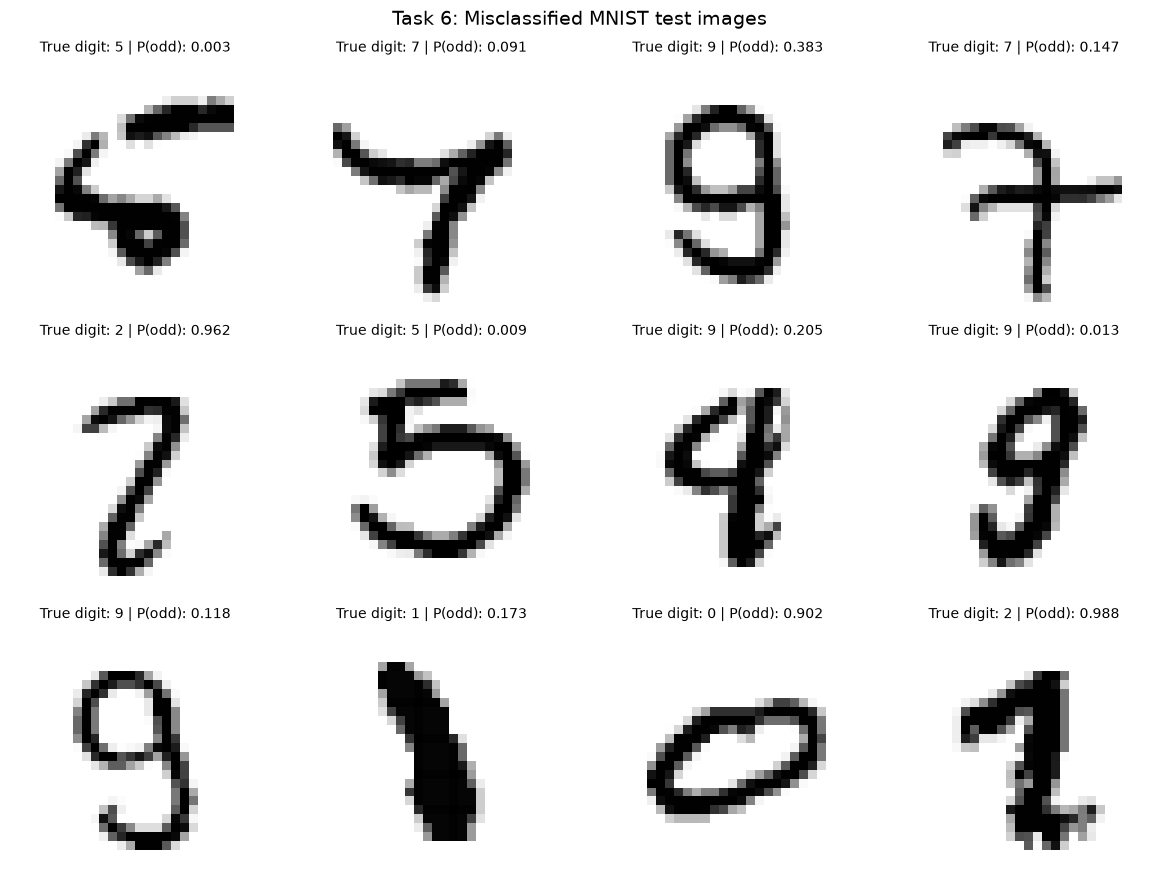


Task 6(c) report helper:
Hardest measured digits: 9, 8, 4
Inspect the 12 displayed images for handwriting patterns.
The classifier only outputs odd/even, not a predicted digit (0-9).
Possible cross-parity shape confusions to discuss, IF supported by images:
  3 (odd) vs 8 (even): extra/closed loops can alter their appearance.
  4 (even) vs 9 (odd): a closed top loop can make forms resemble each other.


In [9]:
# (a) number of errors, error rate per digit
# best_params was selected using the development set in Task 5.
# Reuse the chosen model; do NOT retrain or tune it using test examples.
with torch.no_grad():
    test_probabilities, _ = L_model_forward(X_test, best_params)
    test_predictions = (test_probabilities > 0.5).float()

# Flatten (m, 1) arrays into (m,) so each position denotes one image.
wrong_mask = (test_predictions != Y_test).reshape(-1)
wrong_indices = torch.nonzero(wrong_mask, as_tuple=True)[0]
total_errors = int(wrong_mask.sum().item())
num_test_images = len(digits_test)

print(f"Number of test errors: {total_errors} / {num_test_images}")
print(f"Overall test error rate: {total_errors / num_test_images:.2%}")
print("\nDigit | Images | Errors | Error rate")
print("-" * 39)

digit_error_rates = {}
for digit in range(10):
    digit_mask = (digits_test == digit)
    digit_count = int(digit_mask.sum().item())
    digit_errors = int((wrong_mask & digit_mask).sum().item())
    error_rate = digit_errors / digit_count if digit_count else float("nan")
    digit_error_rates[digit] = error_rate
    print(f"{digit:5d} | {digit_count:6d} | {digit_errors:6d} | {error_rate:9.2%}")

# Rank digits by their own error rate, rather than number of errors alone.
hardest_digits = sorted(digit_error_rates, key=digit_error_rates.get, reverse=True)
print("\nHardest digits by error rate (highest first):")
for digit in hardest_digits[:3]:
    print(f"Digit {digit}: {digit_error_rates[digit]:.2%}")

# (b) at least 12 misclassified test images with the digit and p(odd)
num_to_show = min(12, len(wrong_indices))
if num_to_show == 0:
    print("\nNo misclassified test images were found.")
else:
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for ax in axes.flat:
        ax.axis("off")

    for ax, index in zip(axes.flat, wrong_indices[:num_to_show]):
        i = int(index.item())
        image = X_test[i].reshape(28, 28).cpu()
        digit = int(digits_test[i].item())
        p_odd = float(test_probabilities[i, 0].item())
        ax.imshow(image, cmap="gray_r")
        ax.set_title(f"True digit: {digit} | P(odd): {p_odd:.3f}", fontsize=10)

    fig.suptitle("Task 6: Misclassified MNIST test images", fontsize=14)
    fig.tight_layout()
    plt.show()

    if num_to_show < 12:
        print(f"Only {num_to_show} errors exist; all available errors are shown.")

# Task 6(c) support: identify the most difficult digits based on measured results.
print("\nTask 6(c) report helper:")
print("Hardest measured digits:", ", ".join(str(d) for d in hardest_digits[:3]))
print("Inspect the 12 displayed images for handwriting patterns.")
print("The classifier only outputs odd/even, not a predicted digit (0-9).")
print("Possible cross-parity shape confusions to discuss, IF supported by images:")
print("  3 (odd) vs 8 (even): extra/closed loops can alter their appearance.")
print("  4 (even) vs 9 (odd): a closed top loop can make forms resemble each other.")

### Task 6(c) · Error-analysis discussion (interpret the executed output)

**Hardest digits.** Use the error-rate table generated in Task 6(a), and identify the digits with the **highest error rates**, not simply the highest error counts. The cell prints the three hardest digits automatically. **After running:** record their digit numbers and measured percentages here; results cannot be determined from unexecuted code alone.

**What the mistakes have in common.** Inspect the 12 plotted images. Look for faint or broken strokes, unusually thick strokes, poorly closed loops, tilted digits, and ambiguous handwritten shapes. Only describe patterns that you actually observe in the plots; these are possible causes, not pre-established findings.

**Two plausible cross-parity digit-confusion hypotheses:**

1. **3 (odd) ↔ 8 (even):** Their curved strokes can look similar when a handwritten 3 is nearly closed or an 8 has an incomplete loop. Mistaking one for the other changes the required binary label (1 versus 0).
2. **4 (even) ↔ 9 (odd):** Some handwriting styles produce similar upper loops or angular strokes, especially when parts of the digit are faint. A 4-like versus 9-like interpretation also changes the binary label (0 versus 1).

**Important limitation:** This network produces only `P(odd)`, **not a predicted digit**. Therefore, it is not possible to establish that it specifically predicted “8” for a true “3” from this model's output. The pairs above are **visual hypotheses** to assess against the displayed errors, not observed digit-to-digit predictions. Replace them if the images point to more convincing cross-parity pairs.

**Final answer after executing the notebook:** “My highest error-rate digits were ___ (___%), ___ (___%), and ___ (___%). Across the misclassified images, I observed ___. Two plausible cross-parity look-alike pairs are ___ and ___ because ___.”
